In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/Sample - Superstore.csv',encoding='windows-1252')

In [ ]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

In [ ]:
monthly_sales = df.groupby(
    pd.Grouper(key="Order Date", freq="ME")
)["Sales"].sum().reset_index()

print(monthly_sales.head())

print(monthly_sales.shape)

print(monthly_sales)

  Order Date      Sales
0 2014-01-31   6221.298
1 2014-02-28   1362.506
2 2014-03-31  33887.931
3 2014-04-30  13391.855
4 2014-05-31  11089.235
(48, 2)
   Order Date       Sales
0  2014-01-31   6221.2980
1  2014-02-28   1362.5060
2  2014-03-31  33887.9310
3  2014-04-30  13391.8550
4  2014-05-31  11089.2350
5  2014-06-30  24693.5356
6  2014-07-31  21470.4440
7  2014-08-31  15682.8285
8  2014-09-30  46543.1318
9  2014-10-31  15259.9610
10 2014-11-30  41441.7980
11 2014-12-31  35121.7485
12 2015-01-31   6350.7880
13 2015-02-28   4390.1950
14 2015-03-31  21112.0690
15 2015-04-30  15141.1470
16 2015-05-31   6592.7280
17 2015-06-30   8496.5730
18 2015-07-31  22436.9230
19 2015-08-31  22149.9320
20 2015-09-30  30294.9180
21 2015-10-31  15318.3665
22 2015-11-30  26074.4503
23 2015-12-31  35779.2892
24 2016-01-31   5824.5750
25 2016-02-29   5880.8100
26 2016-03-31  22852.1520
27 2016-04-30  23422.7920
28 2016-05-31  25993.0300
29 2016-06-30  15271.6600
30 2016-07-31  21959.7630
31 2016-08-31  1

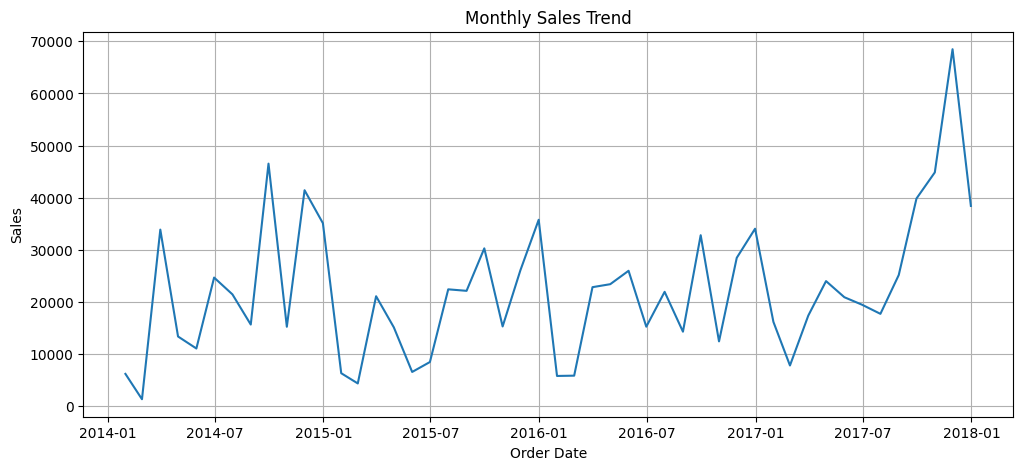

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(monthly_sales["Order Date"],
         monthly_sales["Sales"])

plt.title("Monthly Sales Trend")

plt.xlabel("Order Date")

plt.ylabel("Sales")

plt.grid(True)

plt.show()

In [ ]:
monthly_sales["Year"] = monthly_sales["Order Date"].dt.year
yearly_sales = monthly_sales.groupby("Year")["Sales"].sum().reset_index()
print(yearly_sales)

   Year        Sales
0  2014  266166.2724
1  2015  214137.3790
2  2016  243339.0405
3  2017  340403.3500


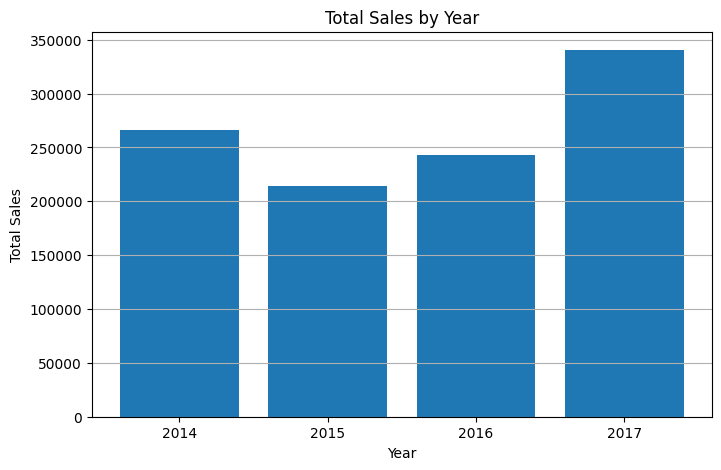

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(
    yearly_sales["Year"].astype(str),
    yearly_sales["Sales"])
plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.grid(axis="y")
plt.show()

In [ ]:
monthly_sales["Month"] = monthly_sales["Order Date"].dt.month_name()
monthly_avg_sales = monthly_sales.groupby("Month")["Sales"].mean().reset_index
print(monthly_avg_sales)


<bound method Series.reset_index of Month
April        18992.894025
August       19332.159575
December     35848.854125
February      4866.463250
January       8648.382000
July         20900.901250
June         16985.822775
March        23813.908200
May          16149.797500
November     41120.691475
October      21973.268375
September    37378.367925
Name: Sales, dtype: float64>


In [ ]:
# Create Month column
monthly_sales["Month"] = monthly_sales["Order Date"].dt.month_name()

# Month order
month_order = [
    "January","February","March","April",
    "May","June","July","August",
    "September","October","November","December"
]

# Calculate average monthly sales
monthly_avg_sales = monthly_sales.groupby("Month")["Sales"].mean().reset_index()

# Convert Month into ordered category
monthly_avg_sales["Month"] = pd.Categorical(
    monthly_avg_sales["Month"],
    categories=month_order,
    ordered=True
)

# Sort by month order
monthly_avg_sales = monthly_avg_sales.sort_values("Month")

# Display
print(monthly_avg_sales)

        Month         Sales
4     January   8648.382000
3    February   4866.463250
7       March  23813.908200
0       April  18992.894025
8         May  16149.797500
6        June  16985.822775
5        July  20900.901250
1      August  19332.159575
11  September  37378.367925
10    October  21973.268375
9    November  41120.691475
2    December  35848.854125


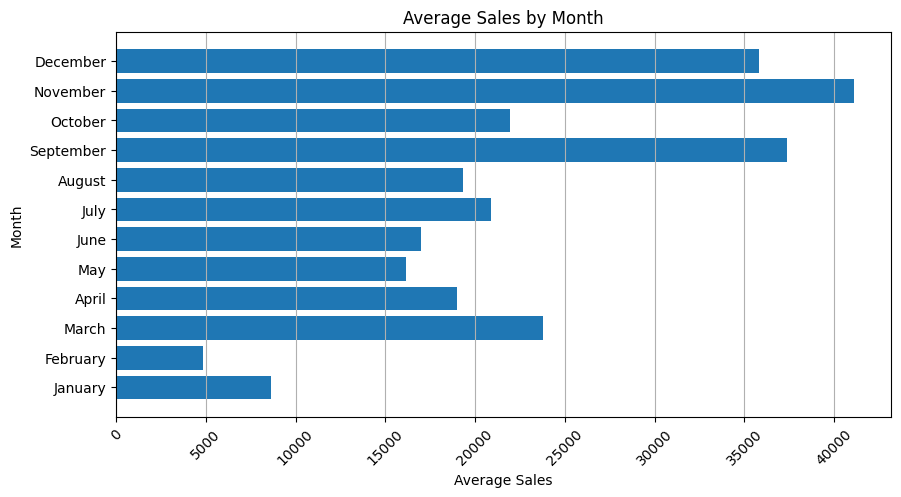

In [ ]:
plt.figure(figsize=(10,5))

plt.barh(monthly_avg_sales["Month"],
        monthly_avg_sales["Sales"])

plt.title("Average Sales by Month")

plt.ylabel("Month")

plt.xlabel("Average Sales")

plt.xticks(rotation=45)

plt.grid(axis="x")

plt.show()

In [ ]:
monthly_sales["Lag_1"] = monthly_sales["Sales"].shift(1)
print(monthly_sales.head())



  Order Date      Sales  Year     Month      Lag_1
0 2014-01-31   6221.298  2014   January        NaN
1 2014-02-28   1362.506  2014  February   6221.298
2 2014-03-31  33887.931  2014     March   1362.506
3 2014-04-30  13391.855  2014     April  33887.931
4 2014-05-31  11089.235  2014       May  13391.855


In [ ]:
monthly_sales["Lag_2"] = monthly_sales["Sales"].shift(2)
print(monthly_sales.head())

#monthly_sales["Lag_3"] = monthly_sales["Sales"].shift(3)



  Order Date      Sales  Year     Month      Lag_1      Lag_2
0 2014-01-31   6221.298  2014   January        NaN        NaN
1 2014-02-28   1362.506  2014  February   6221.298        NaN
2 2014-03-31  33887.931  2014     March   1362.506   6221.298
3 2014-04-30  13391.855  2014     April  33887.931   1362.506
4 2014-05-31  11089.235  2014       May  13391.855  33887.931


In [ ]:
monthly_sales = monthly_sales.dropna()
print(monthly_sales.head())

  Order Date       Sales  Year  Month       Lag_1      Lag_2
2 2014-03-31  33887.9310  2014  March   1362.5060   6221.298
3 2014-04-30  13391.8550  2014  April  33887.9310   1362.506
4 2014-05-31  11089.2350  2014    May  13391.8550  33887.931
5 2014-06-30  24693.5356  2014   June  11089.2350  13391.855
6 2014-07-31  21470.4440  2014   July  24693.5356  11089.235


In [ ]:
#MACHINE LEARNING MODEL INPUT OUTPUT

#INPUT
X = monthly_sales[["Lag_1", "Lag_2"]]

#target
y = monthly_sales["Sales"]

print(X.head())
print(y.head())

print(X.shape)
print(y.shape)

        Lag_1      Lag_2
2   1362.5060   6221.298
3  33887.9310   1362.506
4  13391.8550  33887.931
5  11089.2350  13391.855
6  24693.5356  11089.235
2    33887.9310
3    13391.8550
4    11089.2350
5    24693.5356
6    21470.4440
Name: Sales, dtype: float64
(46, 2)
(46,)


In [ ]:
#TRAIN TEST SPLIT, FIRST CALCULATE HOW MANY ROWS GOES TO TRAINING USING THIS NUMBER OF TEST ROWS CAN ALSO BE INEFERED
train_size = int(len(monthly_sales) * 0.8)

print(train_size)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

36


In [ ]:
#LINEAR REGRESSION MODEL
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(y_pred)

[22191.07171027 22664.60458564 20665.02495801 19919.32139878
 20507.67796926 20871.1887414  20517.91479649 18171.76143958
 15531.90539467 12812.18734263]


In [ ]:
#EVALUATION METRICS

import math

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = math.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 13851.466821987531
MSE : 459789600.2569601
RMSE: 21442.70505922609
R2  : -0.9122246884031797


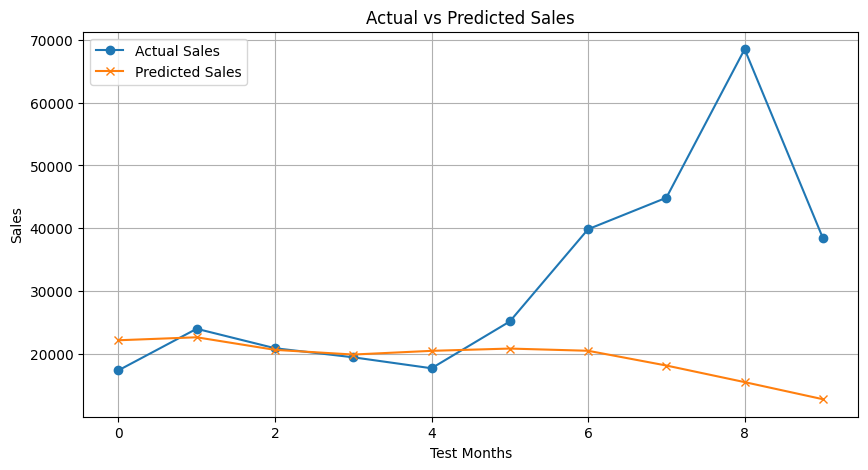

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    y_test.values,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    y_pred,
    label="Predicted Sales",
    marker="x"
)

plt.title("Actual vs Predicted Sales")

plt.xlabel("Test Months")

plt.ylabel("Sales")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
monthly_sales = (
    df.groupby(pd.Grouper(key="Order Date", freq="M"))["Sales"]
      .sum()
      .reset_index()
)

print(monthly_sales.head())
print(monthly_sales.shape)

  Order Date      Sales
0 2014-01-31   6221.298
1 2014-02-28   1362.506
2 2014-03-31  33887.931
3 2014-04-30  13391.855
4 2014-05-31  11089.235
(48, 2)


/tmp/ipykernel_1739/2250786598.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df.groupby(pd.Grouper(key="Order Date", freq="M"))["Sales"]


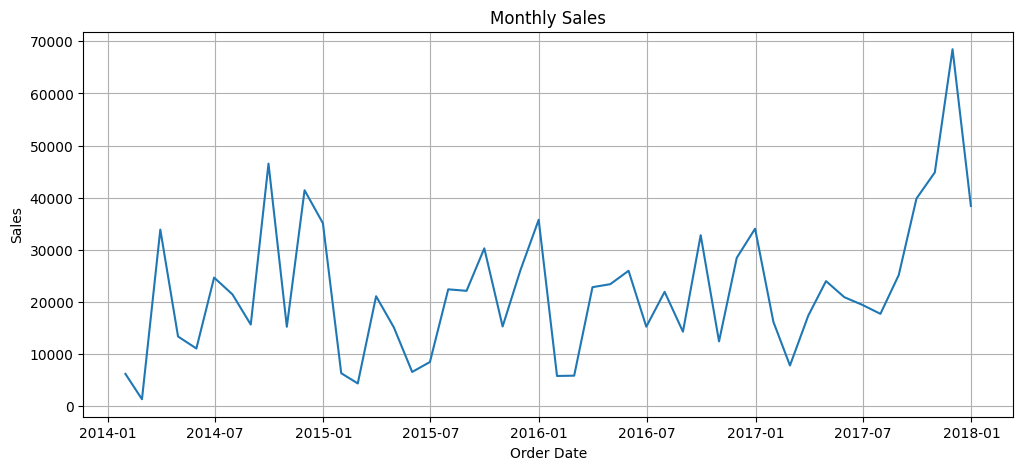

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(monthly_sales["Order Date"], monthly_sales["Sales"])
plt.title("Monthly Sales")
plt.xlabel("Order Date")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

In [ ]:
#DATA CREATION FOR ARIMA MODEL
monthly_sales_arima = (
    df.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
      .sum()
      .reset_index()
)

print(monthly_sales_arima.head())
print(monthly_sales_arima.shape)

  Order Date      Sales
0 2014-01-31   6221.298
1 2014-02-28   1362.506
2 2014-03-31  33887.931
3 2014-04-30  13391.855
4 2014-05-31  11089.235
(48, 2)


In [ ]:
from statsmodels.tsa.stattools import adfuller
result = adfuller(monthly_sales_arima["Sales"])
print("ADF Statistic :", result[0])
print("p-value :", result[1])
print("Lags Used :", result[2])
print("Observations :", result[3])
print("Critical Values :", result[4])

ADF Statistic : -4.892648983989588
p-value : 3.60417598805958e-05
Lags Used : 0
Observations : 47
Critical Values : {'1%': np.float64(-3.5778480370438146), '5%': np.float64(-2.925338105429433), '10%': np.float64(-2.6007735310095064)}


In [ ]:
#ARIMA GRAPHS
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

<Figure size 1000x500 with 0 Axes>

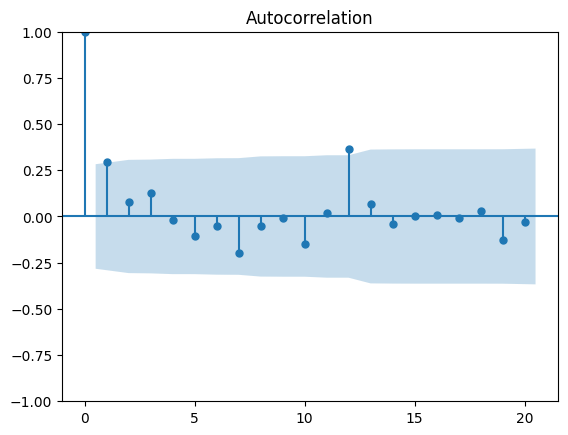

In [ ]:
#ACF GRAPH
plt.figure(figsize=(10,5))
plot_acf(monthly_sales_arima["Sales"], lags=20)
plt.show()

<Figure size 1000x500 with 0 Axes>

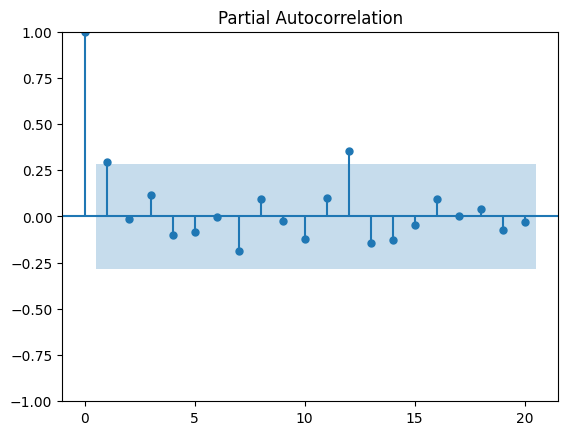

In [ ]:
#PACF GRAPH
plt.figure(figsize=(10,5))
plot_pacf(monthly_sales_arima["Sales"], lags=20)
plt.show()

In [ ]:
#ARIMA MODEL
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(
    monthly_sales_arima["Sales"],
    order=(1,0,0)
)

model_fit = model.fit()

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   48
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -520.796
Date:                Mon, 13 Jul 2026   AIC                           1047.591
Time:                        16:52:13   BIC                           1053.205
Sample:                             0   HQIC                          1049.713
                                 - 48                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.217e+04   2649.753      8.366      0.000     1.7e+04    2.74e+04
ar.L1          0.3072      0.124      2.473      0.013       0.064       0.551
sigma2      1.535e+08      0.086   1.78e+09      0.0

In [ ]:
#ARIMA MODEL 2
from statsmodels.tsa.arima.model import ARIMA

model_1 = ARIMA(
    monthly_sales_arima["Sales"],
    order=(1,0,1)
)

model_fit_1 = model_1.fit()

print(model_fit_1.summary())

                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   48
Model:                 ARIMA(1, 0, 1)   Log Likelihood                -520.737
Date:                Mon, 13 Jul 2026   AIC                           1049.474
Time:                        16:52:13   BIC                           1056.958
Sample:                             0   HQIC                          1052.302
                                 - 48                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.217e+04   2899.867      7.644      0.000    1.65e+04    2.79e+04
ar.L1          0.5727      0.473      1.210      0.226      -0.355       1.500
ma.L1         -0.2851      0.539     -0.529      0.5

In [ ]:
#FORECASTING FUTURE 12 MONTHS SALES
forecast = model_fit.forecast(steps=12)

future_dates = pd.date_range(
    start="2018-01-31",
    periods=12,
    freq="ME"
)

forecast_df = pd.DataFrame({
    "Order Date": future_dates,
    "Forecast Sales": forecast
})

print(forecast_df)

   Order Date  Forecast Sales
48 2018-01-31    27164.717384
49 2018-02-28    23702.940032
50 2018-03-31    22639.338180
51 2018-04-30    22312.555495
52 2018-05-31    22212.154275
53 2018-06-30    22181.306848
54 2018-07-31    22171.829237
55 2018-08-31    22168.917321
56 2018-09-30    22168.022659
57 2018-10-31    22167.747782
58 2018-11-30    22167.663329
59 2018-12-31    22167.637381


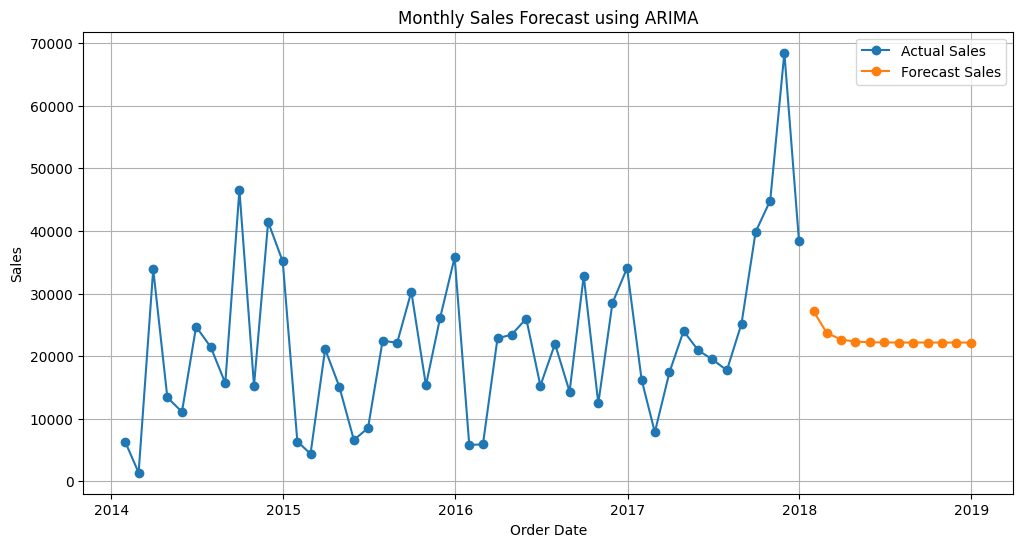

In [ ]:
plt.figure(figsize=(12,6))

# Historical Sales
plt.plot(
    monthly_sales["Order Date"],
    monthly_sales["Sales"],
    label="Actual Sales",
    marker="o"
)

# Forecast Sales
plt.plot(
    forecast_df["Order Date"],
    forecast_df["Forecast Sales"],
    label="Forecast Sales",
    marker="o"
)

plt.title("Monthly Sales Forecast using ARIMA")
plt.xlabel("Order Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

Training Rows : 36
Testing Rows  : 12


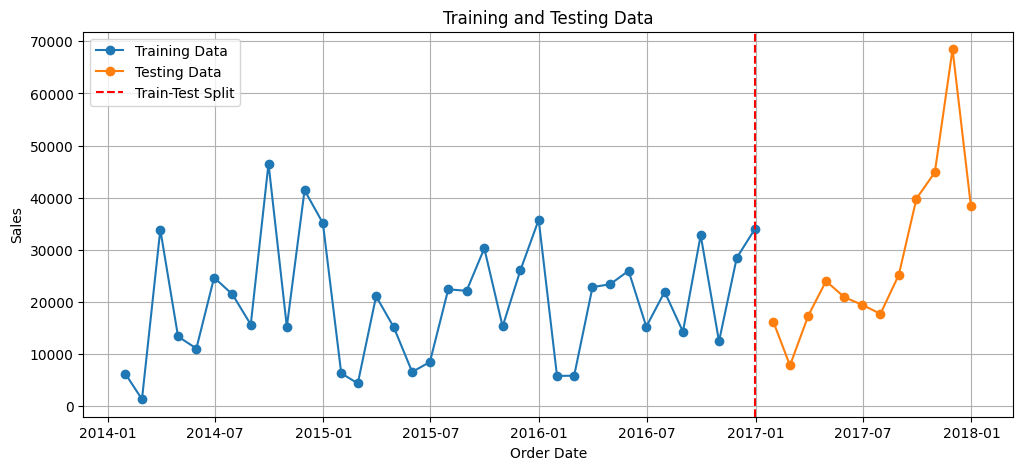


Evaluation Metrics
---------------------------
MAE  : 11889.638218480237
MSE  : 324954494.47077197
RMSE : 18026.49423683851
MAPE : 39.57581875761662

Comparison Table
         Date  Actual Sales  Predicted Sales
0  2017-01-31    16196.8670     19873.592126
1  2017-02-28     7832.3420     20104.896093
2  2017-03-31    17403.4808     20101.125403
3  2017-04-30    24015.7821     20101.186872
4  2017-05-31    20924.1970     20101.185870
5  2017-06-30    19481.5225     20101.185886
6  2017-07-31    17736.4750     20101.185886
7  2017-08-31    25180.1260     20101.185886
8  2017-09-30    39853.8240     20101.185886
9  2017-10-31    44861.6020     20101.185886
10 2017-11-30    68485.1318     20101.185886
11 2017-12-31    38431.9998     20101.185886


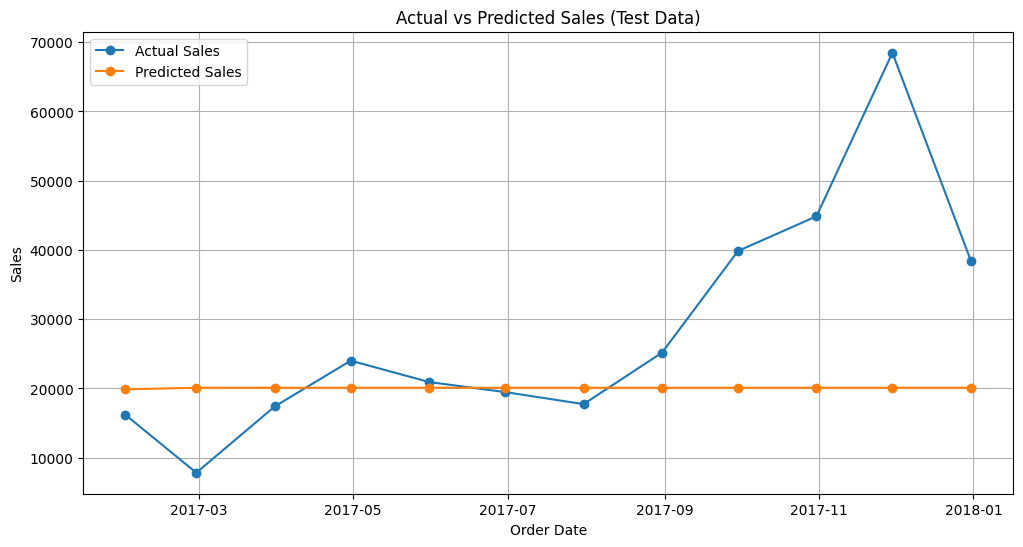


Forecast for 2018
   Order Date  Forecast Sales
0  2018-01-31    27164.717384
1  2018-02-28    23702.940032
2  2018-03-31    22639.338180
3  2018-04-30    22312.555495
4  2018-05-31    22212.154275
5  2018-06-30    22181.306848
6  2018-07-31    22171.829237
7  2018-08-31    22168.917321
8  2018-09-30    22168.022659
9  2018-10-31    22167.747782
10 2018-11-30    22167.663329
11 2018-12-31    22167.637381


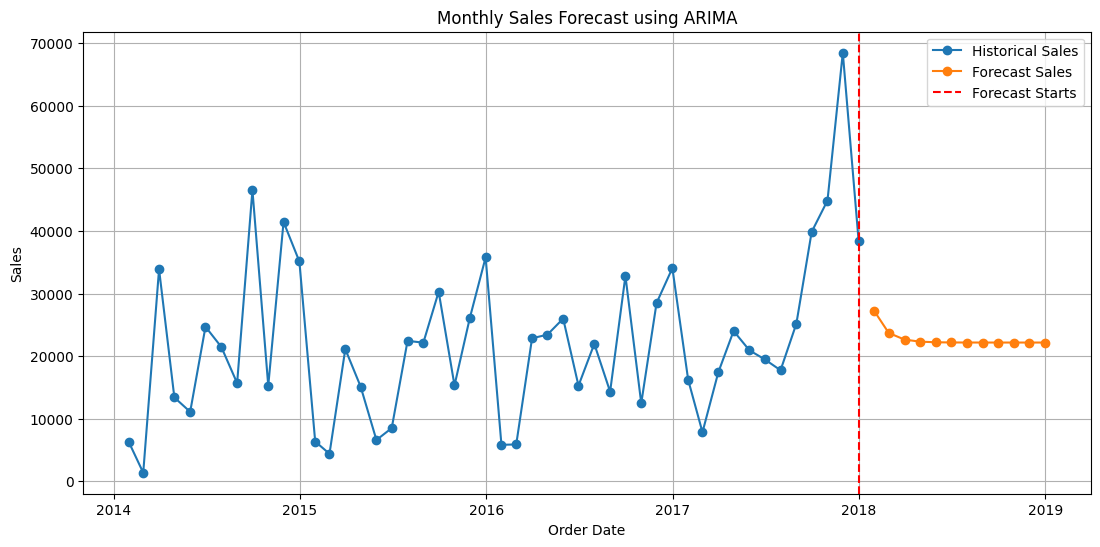

In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Train-Test Split
train = monthly_sales.iloc[:36]
test = monthly_sales.iloc[36:]

print("Training Rows :", len(train))
print("Testing Rows  :", len(test))

# Plot Train-Test Split
plt.figure(figsize=(12,5))

plt.plot(train["Order Date"], train["Sales"],
         label="Training Data", marker='o')

plt.plot(test["Order Date"], test["Sales"],
         label="Testing Data", marker='o')

plt.axvline(train["Order Date"].iloc[-1],
            color='red',
            linestyle='--',
            label='Train-Test Split')

plt.title("Training and Testing Data")
plt.xlabel("Order Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

# Train ARIMA Model
model = ARIMA(train["Sales"], order=(1,0,0))
model_fit = model.fit()

# Predict Test Data (2017)
predictions = model_fit.forecast(steps=len(test))

# Evaluation Metrics
mae = mean_absolute_error(test["Sales"], predictions)
mse = mean_squared_error(test["Sales"], predictions)
rmse = np.sqrt(mse)


mape = np.mean(np.abs((test["Sales"] - predictions) / test["Sales"])) * 100

print("\nEvaluation Metrics")
print("---------------------------")
print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("MAPE :", mape)

# Actual vs Predicted
comparison = pd.DataFrame({
    "Date": test["Order Date"].values,
    "Actual Sales": test["Sales"].values,
    "Predicted Sales": predictions.values
})

print("\nComparison Table")
print(comparison)

# Plot Actual vs Predicted
plt.figure(figsize=(12,6))

plt.plot(test["Order Date"],
         test["Sales"],
         marker='o',
         label="Actual Sales")

plt.plot(test["Order Date"],
         predictions,
         marker='o',
         label="Predicted Sales")

plt.title("Actual vs Predicted Sales (Test Data)")
plt.xlabel("Order Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

# Final Model on Complete Dataset
final_model = ARIMA(monthly_sales["Sales"], order=(1,0,0))
final_model_fit = final_model.fit()

# Forecast Next 12 Months
future_forecast = final_model_fit.forecast(steps=12)

future_dates = pd.date_range(
    start="2018-01-31",
    periods=12,
    freq="ME"
)

forecast_df = pd.DataFrame({
    "Order Date": future_dates,
    "Forecast Sales": future_forecast.values
})

print("\nForecast for 2018")
print(forecast_df)

# Final Forecast Plot
plt.figure(figsize=(13,6))

plt.plot(monthly_sales["Order Date"],
         monthly_sales["Sales"],
         marker='o',
         label="Historical Sales")

plt.plot(forecast_df["Order Date"],
         forecast_df["Forecast Sales"],
         marker='o',
         label="Forecast Sales")

plt.axvline(monthly_sales["Order Date"].max(),
            color='red',
            linestyle='--',
            label='Forecast Starts')

plt.title("Monthly Sales Forecast using ARIMA")
plt.xlabel("Order Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()